In [ ]:
# Insurance Premium Prediction & Risk Modeling

This notebook performs two main tasks:

1. **Severity Modeling** (Regression): Predict total claim amounts for customers who had a claim.
2. **Probability Modeling** (Classification): Predict the likelihood that a customer will make a claim.

The final output includes SHAP explanations and predicted premiums.


In [7]:
# 1. Imports and Setup
import pandas as pd
import numpy as np
!pip install scikit-learn
!pip install xgboost shap

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import (
    mean_squared_error, r2_score, accuracy_score,
    precision_score, recall_score, f1_score
)
import shap
import matplotlib.pyplot as plt
import logging
from pathlib import Path

# Setup logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s')
Path('docs').mkdir(parents=True, exist_ok=True)
Path('notebooks/plots').mkdir(parents=True, exist_ok=True)



[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 23.2.1 -> 25.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


  Obtaining dependency information for xgboost from https://files.pythonhosted.org/packages/29/22/e3ff2dfafe862a91733dfa0aecdb4794aa1d9a18e09a14e118bde0cbc2db/xgboost-3.0.2-py3-none-win_amd64.whl.metadata
  Using cached xgboost-3.0.2-py3-none-win_amd64.whl.metadata (2.1 kB)
  Obtaining dependency information for shap from https://files.pythonhosted.org/packages/8b/34/3dd677ef2a98b74c95188a3fc248cfcb81670a1410ef388f063c962616fa/shap-0.48.0-cp312-cp312-win_amd64.whl.metadata
  Using cached shap-0.48.0-cp312-cp312-win_amd64.whl.metadata (25 kB)
  Obtaining dependency information for slicer==0.0.8 from https://files.pythonhosted.org/packages/63/81/9ef641ff4e12cbcca30e54e72fb0951a2ba195d0cda0ba4100e532d929db/slicer-0.0.8-py3-none-any.whl.metadata
  Using cached slicer-0.0.8-py3-none-any.whl.metadata (4.0 kB)
  Obtaining dependency information for numba>=0.54 from https://files.pythonhosted.org/packages/68/1d/ddb3e704c5a8fb90142bf9dc195c27db02a08a99f037395503bfbc1d14b3/numba-0.61.2-cp312-cp3

c:\Users\dagi\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [9]:
## 2. Load Dataset
try:
    df = pd.read_csv('../data/MachineLearningRating_v3_cleaned.txt', sep='|', low_memory=False)
    logging.info("Dataset loaded successfully")
except FileNotFoundError:
    logging.error("Dataset not found. Run src/preprocess_data.py and dvc pull.")
    raise


2025-06-16 07:53:11,834 - INFO - Dataset loaded successfully


In [10]:
## 3. Preprocessing and Feature Engineering
# Convert key columns to numeric
numeric_cols = ['TotalClaims', 'TotalPremium', 'SumInsured', 'RegistrationYear']
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')
df.dropna(subset=numeric_cols, inplace=True)

# Feature engineering
df['VehicleAge'] = 2015 - df['RegistrationYear']
df['IsNewVehicle'] = (df['NewVehicle'] == 'New').astype(int)
df['PremiumPerSumInsured'] = df['TotalPremium'] / df['SumInsured'].clip(lower=1)
df['HasClaim'] = (df['TotalClaims'] > 0).astype(int)

# Group rare categories
cat_cols = ['Province', 'VehicleType', 'CoverType', 'Gender', 'MaritalStatus']
for col in cat_cols:
    if col in df.columns:
        rare = df[col].value_counts()[df[col].value_counts() < 0.01 * len(df)].index
        df[col] = df[col].apply(lambda x: 'Other' if x in rare else x)
    else:
        df[col] = 'Unknown'
    df[col] = df[col].fillna('Unknown')

# One-hot encoding
df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Encode PostalCode
if 'PostalCode' in df.columns:
    le = LabelEncoder()
    df['PostalCode'] = le.fit_transform(df['PostalCode'].astype(str))


In [11]:
## 4. Train/Test Split for Severity and Probability
drop_cols = ['TotalClaims', 'HasClaim', 'TotalPremium', 'NewVehicle', 'Bank', 'AccountType', 'TransactionMonth', 'LossRatio']
features = [col for col in df.columns if col not in drop_cols]

# Filter and align
X_severity = df[df['HasClaim'] == 1][features].apply(pd.to_numeric, errors='coerce')
y_severity = np.log1p(df[df['HasClaim'] == 1]['TotalClaims'])

X_prob = df[features].apply(pd.to_numeric, errors='coerce')
y_prob = df['HasClaim']

# Drop missing columns
X_severity = X_severity.dropna(axis=1)
X_prob = X_prob[X_severity.columns]
X_severity.dropna(inplace=True)
X_prob.dropna(inplace=True)
y_severity = y_severity.loc[X_severity.index]
y_prob = y_prob.loc[X_prob.index]

# Split
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(X_severity, y_severity, test_size=0.2, random_state=42)
X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_prob, y_prob, test_size=0.2, random_state=42)


In [12]:
## 5. Model Training - Severity (Regression)
models_s = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(random_state=42),
    'XGBoost': XGBRegressor(random_state=42)
}

results_s = []
for name, model in models_s.items():
    if name in ['Random Forest', 'XGBoost']:
        param_grid = {'n_estimators': [50, 100], 'max_depth': [10, 20]}
        grid = GridSearchCV(model, param_grid, cv=3, scoring='neg_mean_squared_error')
        grid.fit(X_train_s, y_train_s)
        model = grid.best_estimator_
    else:
        model.fit(X_train_s, y_train_s)

    y_pred = model.predict(X_test_s)
    results_s.append({
        'Model': name,
        'RMSE': np.sqrt(mean_squared_error(y_test_s, y_pred)),
        'R-squared': r2_score(y_test_s, y_pred)
    })
    models_s[name] = model


In [13]:
## 6. Model Training - Probability (Classification)
models_p = {
    'Random Forest': RandomForestClassifier(random_state=42, class_weight='balanced'),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=len(y_train_p[y_train_p == 0]) / len(y_train_p[y_train_p == 1]))
}

results_p = []
for name, model in models_p.items():
    param_grid = {'n_estimators': [50, 100], 'max_depth': [10, 20]}
    grid = GridSearchCV(model, param_grid, cv=3, scoring='f1')
    grid.fit(X_train_p, y_train_p)
    model = grid.best_estimator_

    y_pred = model.predict(X_test_p)
    cv_scores = cross_val_score(model, X_train_p, y_train_p, cv=5, scoring='f1')

    results_p.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test_p, y_pred),
        'Precision': precision_score(y_test_p, y_pred),
        'Recall': recall_score(y_test_p, y_pred),
        'F1-score': f1_score(y_test_p, y_pred),
        'CV F1 Mean': cv_scores.mean(),
        'CV F1 Std': cv_scores.std()
    })
    models_p[name] = model


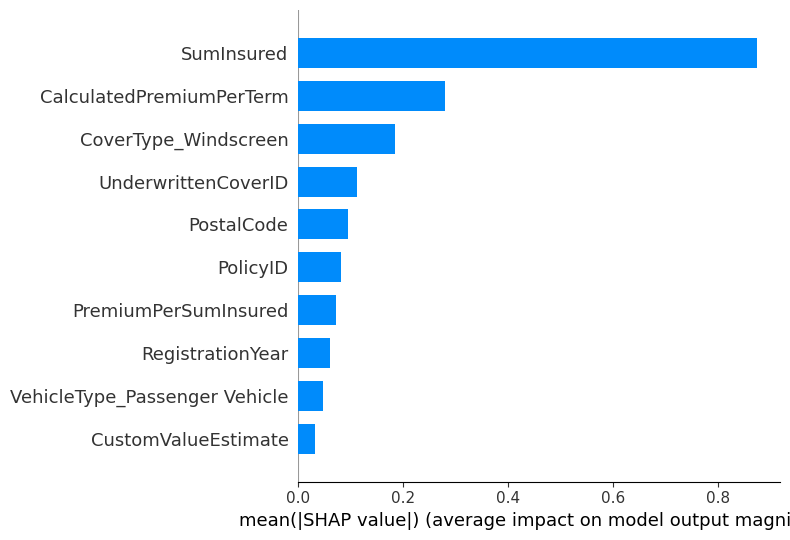

In [14]:
## 7. SHAP Explanation for Severity Model (XGBoost)
xgb_s = models_s.get('XGBoost')
shap_features = []

if xgb_s:
    xgb_s.fit(X_train_s, y_train_s)
    explainer = shap.Explainer(xgb_s)
    shap_values = explainer(X_test_s)

    shap.summary_plot(shap_values, X_test_s, plot_type="bar", max_display=10)
    
    shap_importance = pd.DataFrame({
        'Feature': X_test_s.columns,
        'Importance': np.abs(shap_values.values).mean(axis=0)
    }).sort_values('Importance', ascending=False).head(10)

    shap_features = shap_importance


In [15]:
## 8. Premium Calculation
if 'XGBoost' in models_p and xgb_s:
    prob_pred = models_p['XGBoost'].predict_proba(X_test_p)[:, 1]
    severity_pred = xgb_s.predict(X_test_p)
    premium = prob_pred * severity_pred + 0.1 * severity_pred + 0.15 * prob_pred * severity_pred

    premium_df = pd.DataFrame({'PredictedPremium': premium})
    premium_df.head()


In [ ]:
## 9. Save Results
results_s_df = pd.DataFrame(results_s)
results_p_df = pd.DataFrame(results_p)

results_s_df.to_csv('docs/severity_model_results.csv', index=False)
results_p_df.to_csv('docs/probability_model_results.csv', index=False)

if shap_features:
    shap_features.to_csv('docs/shap_features.csv', index=False)

premium_df.to_csv('docs/predicted_premiums.csv', index=False)


In [ ]:
## 10. Display Final Results
print("Severity Model Results:")
display(results_s_df)

print("\nProbability Model Results:")
display(results_p_df)

if shap_features:
    print("\nTop SHAP Features:")
    display(shap_features)
